Refine the analysis of your project.

1) Try clustering.

2) Do dimensional analysis

3) Visualize and create a narrative about what you have discovered in the data. Don't just be descriptive, think predictively.

4) Is there anomalous data? What does it mean?

5) Explore more advanced regression/classifier tools.  (Random Forrest is interesting, Neural Nets are king.)



# Try clustering

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

df = pd.read_csv("world_bank_data_2025.csv")
df['Log_GDP_per_Capita'] = np.log(df['GDP per Capita (Current USD)'])

features = [
    'Interest Rate (Real, %)',
    'Government Expense (% of GDP)',
    'Tax Revenue (% of GDP)',
    'Gross National Income (USD)',
    'GDP per Capita (Current USD)',
    'Unemployment Rate (%)'
]

clean_df = df[features].dropna().copy()

clean_df['LogPerCapita'] = np.log(clean_df['GDP per Capita (Current USD)'])

X_features = [
    'Interest Rate (Real, %)',
    'Government Expense (% of GDP)',
    'Gross National Income (USD)',
    'Tax Revenue (% of GDP)',
    'Unemployment Rate (%)'
]

X = clean_df[X_features]
y = clean_df['LogPerCapita']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_scaled)
test_clusters = kmeans.predict(X_test_scaled)
train_distances = kmeans.transform(X_train_scaled)
test_distances = kmeans.transform(X_test_scaled)

dt_reg = DecisionTreeRegressor(max_depth= 6, min_samples_split=10, min_samples_leaf=5, random_state=42)
dt_reg.fit(X_train_scaled, y_train)

y_pred = dt_reg.predict(X_test_scaled)

print("Test RMSE:", mean_squared_error(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test R2:", r2_score(y_test, y_pred))


Test RMSE: 0.4926700262217147
Test MAE: 0.5239794260766037
Test R2: 0.7112605494501587


# Findings
This DecisionTree Regressor has done a good job of predicting data. My findings originally showed that the model could accurately predict about 69% of the variance in y feature (LogGDPPerCapita) which isn't bad but it's definitely not super strong. Despite this lower score, there was a possibility that the tree was overfitting and creating splits based on noise. To combat this, I managed additional hyperparameters such as max_depth, min_samples_split, and min_samples_leaf. What I found after the fact, I found that my r2 score increased but my MAE increased as well with my RMSE decreasing. This means that extremes were caught more often by the model (which increased the r2 score) but the model became slightly less effective at predicting LogGDP's closer to the median LogGPD. 

## Next - Do dimensional analysis

----2D ScatterPlot----

Explained Variance Ratio: [0.35404763 0.21313962]
Total Variance Explained: 0.5671872491902622


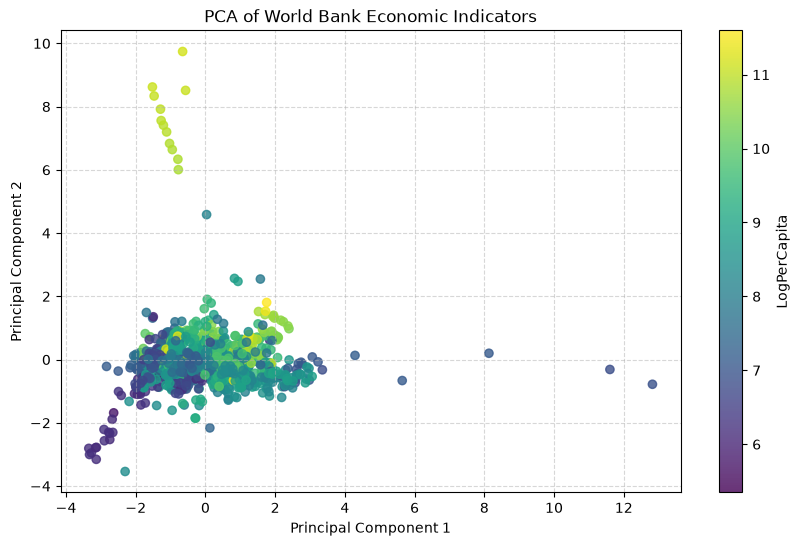

----3D ScatterPlot----

Explained Variance Ratio: [0.35404763 0.21313962 0.182946  ]
Total Variance Explained: 0.7501332476993375


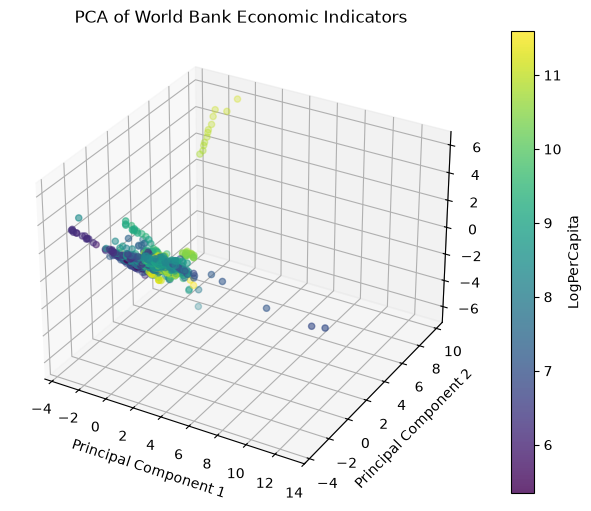

In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#2D Visualization
print("----2D ScatterPlot----\n")
pca = PCA(n_components=2, random_state=42) #want to have more than 2 components
X_pca = pca.fit_transform(X_scaled)

#What is the tuple/duple that is printed by pca.explained_variance_ratio? What do both these metrics mean?
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", sum(pca.explained_variance_ratio_))

#Visualization
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
scatter = plt.scatter( #not sure how to make more than 2 components work with visualization
    X_pca[:, 0], 
    X_pca[:, 1],   
    c=y, 
    cmap='viridis', 
    alpha=0.8
)
plt.colorbar(scatter, label='LogPerCapita')
plt.title('PCA of World Bank Economic Indicators')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#3D Scatterplot Visualization
print("----3D ScatterPlot----\n")
pca = PCA(n_components=3, random_state=42) #want to have more than 2 components
X_pca = pca.fit_transform(X_scaled)

#What is the tuple/duple that is printed by pca.explained_variance_ratio? What do both these metrics mean?
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", sum(pca.explained_variance_ratio_))

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection = '3d')
scatter = ax.scatter( #not sure how to make more than 2 components work with visualization
    X_pca[:, 0], 
    X_pca[:, 1], 
    X_pca[:, 2],  
    c=y, 
    cmap='viridis', 
    alpha=0.8
)
plt.colorbar(scatter, label='LogPerCapita')
plt.title('PCA of World Bank Economic Indicators')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



Using PCA, I attempted to see how many patterns I could detect in the data. Originally, I was only able to detect a little over 50% of the pattern/achieve accurate predictions. When I upgraded the number of components to 3, I used a 3d projection scatterplot to visualize it and while more of the variance is explained by the model (around 70%), it's not clear to distinguish visually. For that reason, I added back the 2 component PCA and it's visualization. I think that while less data/variance is explained, the visualization is more helpful. Helpful reminder: PCA takes 5 features and mashes them down to 2, or how many were requested.

     Interest Rate (Real, %)  Government Expense (% of GDP)  \
PC1                -0.236267                       0.629086   
PC2                -0.562592                       0.068470   
PC3                 0.711785                       0.143148   

     Gross National Income (USD)  Tax Revenue (% of GDP)  \
PC1                    -0.059029                0.620317   
PC2                     0.793422               -0.072952   
PC3                     0.583015               -0.051477   

     Unemployment Rate (%)  
PC1               0.400189  
PC2              -0.209669  
PC3               0.360991  


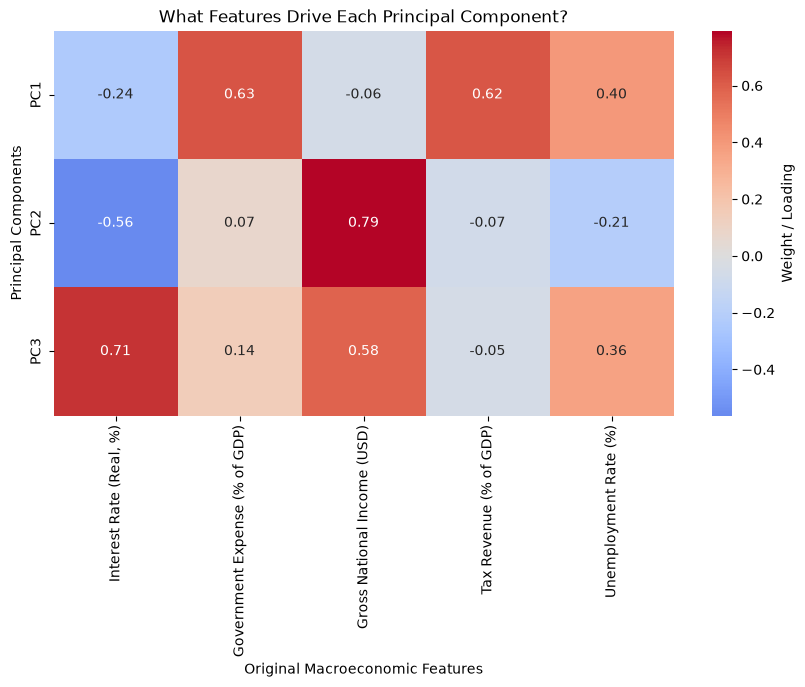

In [4]:
import seaborn as sns

loadings = pd.DataFrame(
    pca.components_, 
    columns=X_features, 
    index=[f'PC{i+1}' for i in range(len(pca.components_))]
)

# Display the loadings matrix
print(loadings)

plt.figure(figsize=(10, 5))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f', cbar_kws={'label': 'Weight / Loading'})
plt.title('What Features Drive Each Principal Component?')
plt.xlabel('Original Macroeconomic Features')
plt.ylabel('Principal Components')
plt.show()

This code above is intended to show me what each component of the PCA is using/weighting each feature. This is helpful in bringing context to the performance of each PCA. Values here show the correlation that each component uses to explain data. If interest rate has a correlation/weight of -.24, then countries further out on the positive side of that component tend to have lower interest rates.

# Visualize and create a narrative about what you have discovered in the data. Don't just be descriptive, think predictively. - PCA Visualization above ^

Global macroeconomic indicators—real interest rates, government expense, tax revenue, gross national income (GNI), and unemployment—do not vary independently. When compressed into principal components (such as PC1 capturing ~35.4% and PC2 capturing ~21.3% of variance), the data forms a visible gradient along LogPerCapita rather than random noise.

Predictive implication: Because economies cluster into recognizable structural profiles, soft distances to K-Means centroids give a downstream model continuous information about where a country sits relative to established economic archetypes. Rather than forcing a split on a single raw indicator in isolation, the model can use multi-dimensional proximity to estimate baseline LogPerCapita.

# Is there anomalous data? What does it mean?

Yes. As seen in the 2d scatterplot, there is anomalous data on the far right of the chart along the x axis (principal component 1). These data points are well outside the main cluster. It means that there are countries that have high Gross National Income (an example feature) which should (according to the 1st principal component) have a high LogPerCapita, but in reality, the said country does not have a high LogPerCapita. Thinking predictively, these outliers/anomalies can distort groupings or clusters.

# Explore more advanced regression/classifier tools.  (Random Forrest is interesting, Neural Nets are king.)

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import KBinsDiscretizer

X = clean_df[X_features]
y = clean_df["LogPerCapita"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

binner = KBinsDiscretizer(n_bins=8, encode="ordinal", strategy="quantile")
y_train_cls = binner.fit_transform(y_train.reshape(-1, 1)).ravel().astype(int)
y_test_cls = binner.transform(y_test.reshape(-1, 1)).ravel().astype(int)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)
train_distances = kmeans.transform(X_train_scaled)
test_distances = kmeans.transform(X_test_scaled)
X_train_aug = np.hstack([X_train_scaled, train_distances])
X_test_aug = np.hstack([X_test_scaled, test_distances])

rf_clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_clf.fit(X_train_aug, y_train_cls)
y_pred_cls = rf_clf.predict(X_test_aug)

print("Test Accuracy:\n", accuracy_score(y_test_cls, y_pred_cls))
print("Classification Report:\n", classification_report(y_test_cls, y_pred_cls))
print("Confusion Matrix:\n", confusion_matrix(y_test_cls, y_pred_cls))

Test Accuracy:
 0.6863636363636364
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.61      0.69        28
           1       0.52      0.77      0.62        22
           2       0.55      0.55      0.55        29
           3       0.74      0.65      0.69        31
           4       0.62      0.55      0.58        29
           5       0.67      0.69      0.68        26
           6       0.85      0.77      0.81        30
           7       0.80      0.96      0.87        25

    accuracy                           0.69       220
   macro avg       0.69      0.69      0.69       220
weighted avg       0.70      0.69      0.69       220

Confusion Matrix:
 [[17  4  3  2  2  0  0  0]
 [ 2 17  2  0  0  0  0  1]
 [ 2  4 16  1  2  1  1  2]
 [ 0  0  7 20  4  0  0  0]
 [ 0  6  0  1 16  6  0  0]
 [ 0  1  0  2  2 18  2  1]
 [ 0  1  1  1  0  2 23  2]
 [ 0  0  0  0  0  0  1 24]]


The Random Forest Classifier seems to be pretty effective at predicting what bin of income_tier a country actually falls into. That being said, originally, I had 4 bins (Low, Lower Middle, Higher Middle, and High income tiers) but I played around and changed it to 8. Then I changed it to 5. Where are the different accuracies with each different # of bins. 4: 81.36%, 5: 70.45%, 8: 68.63%. I think organizing the world's country's LogPerCapita into 4 bins is a gross generalization. I think 5-6 bins is more appropriate for representing data accurately. I mean I could do 2 bins and have great success from a model standpoint but that's not particularly helpful when the objective is accurate predictions of Income tiers for different countries around the world.

In [10]:
from sklearn.neural_network import MLPRegressor

mlp_reg = MLPRegressor(
    hidden_layer_sizes=(64, 32),  
    activation="relu",
    solver="adam",
    alpha=0.01,                   # L2 regularization to curb overfitting
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42
)

mlp_reg.fit(X_train_aug, y_train)
y_pred_mlp_reg = mlp_reg.predict(X_test_aug)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MLP Regressor — R²: {r2:.3f}, RMSE: {rmse:.3f}, MAE: {mae:.3f}")

MLP Regressor — R²: 0.711, RMSE: 0.702, MAE: 0.524


MLP Regressor performed really well considering that it's regression. I say that because the classifier from before (RandomForestClassifier) had a higher accuracy 80% but those are large-encompassing bins, where as this tackles continuous values of LogPerCapita.

Comparing all the different kinds of classifiers and regression models put together in this file, it's interesting that the DecisionTreeRegressor and the MLP Regressor actually had the same r2 score. 

After doing some looking online, the fact that the neural net and the DecisionTreeRegressor scored about the same (with the DTR coming out on top slightly because of a lower/better RMSE) can be explained by how deep/how much information is in the data set as well as the different methods of which both models accomplish finding their predictions. DecisionTrees typically have a lot of success with tabular data, while Neural Nets shine with an abundance of data for them to be trained on.